# Estimate variance-based input sensitivity

**Question:** How does the estimate variance-based input sensitivity analysis change when the same authored ore is run at controlled throughput settings?

Level: 3. Prerequisites: Levels 1 and 2 of this topic and level 3 of learning. Reading time: 32 minutes.

## Objectives

Run the production Saltelli-Sobol sensitivity method on a bounded teaching design, rank first-order and total effects, and explain why small-design indices are exploratory estimates.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

Configure imports and record versions. This makes the method run reproducible.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; input ranges and output definitions are persisted in `data/derived/benchmark.json` and `data/derived/contract/operating_contract.json`, MIT project licence. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

For independent uncertain inputs, first-order Sobol indices measure variance explained by one input and total indices include interactions. SALib builds the scrambled Sobol design and estimates indices; OreFlow runs every design row through the same solver. The teaching design uses a small base size to keep execution short. It is not a substitute for the production-sized sensitivity record or an empirical plant analysis.

## Comparison

Saltelli et al. (2010) give variance-based estimators for first-order and total-order effects; SALib (Herman and Usher, 2017) supplies the design and analysis implementation. OreFlow documents that its bootstrap resamples low-discrepancy design rows as independent and can overstate uncertainty bounds. The small teaching run is a reproducible method demonstration, not a novel estimator or validated field sensitivity.

Call OreFlow's production sensitivity method with a seeded, teaching-sized Sobol base design.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.methods.uncertainty import sensitivity

# Load this notebook's authored case in its fresh kernel.
case = next(item for item in CASES if item.id == "copper_porphyry_soft")

# Evaluate the product implementation; each factor draw is passed to the engine.
indices = sensitivity(case, case.nominal, base_samples=64, seed=20261027)
print(
    "status:",
    indices["status"],
    "| base rows:",
    indices["base_samples"],
    "| engine evaluations:",
    indices["evaluations"],
)
print("inputs and half-widths:", indices["inputs"])


status: computed | base rows: 64 | engine evaluations: 384
inputs and half-widths: {'work_index': {'half_width': 0.2}, 'head_grade': {'half_width': 0.2}, 'liberation_size': {'half_width': 0.25}, 'floatability': {'half_width': 0.25}}


Extract first-order and total indices for recovery. Compare their order but retain their sampling uncertainty.

In [3]:
# Extract first-order and total indices for recovery.
effects = indices["indices"]["recovery_pct"]
if effects.get("constant"):
    print("Recovery is constant at the declared numerical tolerance; no ranking is meaningful.")
else:
    table = pd.DataFrame(
        [
            {
                "input": name,
                "first order": effects["S1"][name],
                "first-order half width": effects["S1_conf"][name],
                "total order": effects["ST"][name],
                "total-order half width": effects["ST_conf"][name],
            }
            for name in indices["inputs"]
        ]
    )
    display(table.sort_values("total order", ascending=False).set_index("input"))


,first order,first-order half width,total order,total-order half width
input,,,,
floatability,0.792495,0.277864,0.799238,0.220069
work_index,0.105186,0.141220,0.140280,0.068846
liberation_size,0.093664,0.090001,0.085582,0.036150
head_grade,0.004543,0.019306,0.003666,0.001483


Plot total-order effects with the reported bootstrap half-widths. Negative estimates or total below first order can arise from finite-sample error.

Interpretation boundary: simulated response under authored factor ranges; not plant causality.


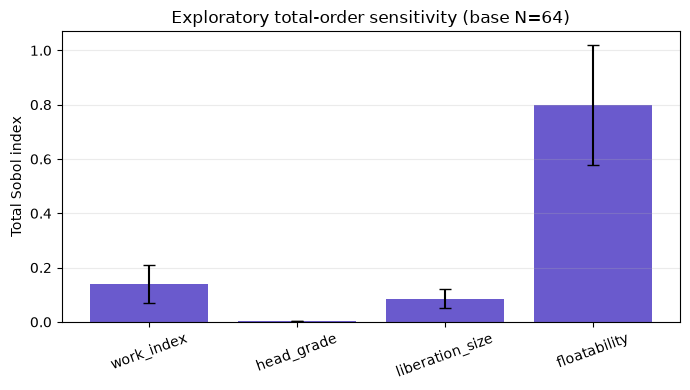

In [4]:
# Plot total-order effects with the reported bootstrap half-widths.
if not effects.get("constant"):
    names = list(indices["inputs"])
    values = np.asarray([effects["ST"][name] for name in names])
    errors = np.asarray([effects["ST_conf"][name] for name in names])
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(names, values, yerr=errors, capsize=4, color="slateblue")
    ax.set(ylabel="Total Sobol index", title="Exploratory total-order sensitivity (base N=64)")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(True, axis="y", alpha=0.25)
    fig.tight_layout()
print(
    "Interpretation boundary: simulated response under authored factor ranges; not plant causality."
)


For the level 3 05 uncertainty case, only fresh-feed rate changes at 0.8 times nominal throughput. This level 3 05 uncertainty comparison at 0.8 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

Figure 14 of level 3 05 uncertainty summarizes solved OreFlow circuits at the stated settings. Its connecting line guides comparison only, not a fitted response law or confidence band. Read the plotted recovery and energy coordinates against the paired run records before comparing candidate settings.

In [5]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_1 = 0.8
point_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_1)
response_1 = simulate(case.ore, case.plant, point_1)
print('throughput (t/h):', round(point_1.throughput_tph, 2))
print('recovery (%):', round(response_1.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_1.metrics['p80_um'], 2))

throughput (t/h): 576.0
recovery (%): 93.788
product P80 (µm): 150.0


For the level 3 05 uncertainty case, only fresh-feed rate changes at 0.9 times nominal throughput. This level 3 05 uncertainty comparison at 0.9 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [6]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_2 = 0.9
point_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_2)
response_2 = simulate(case.ore, case.plant, point_2)
print('throughput (t/h):', round(point_2.throughput_tph, 2))
print('recovery (%):', round(response_2.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_2.metrics['p80_um'], 2))

throughput (t/h): 648.0
recovery (%): 92.996
product P80 (µm): 150.0


For the level 3 05 uncertainty case, only fresh-feed rate changes at 1.0 times nominal throughput. This level 3 05 uncertainty comparison at 1.0 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [7]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_3 = 1.0
point_3 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_3)
response_3 = simulate(case.ore, case.plant, point_3)
print('throughput (t/h):', round(point_3.throughput_tph, 2))
print('recovery (%):', round(response_3.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_3.metrics['p80_um'], 2))

throughput (t/h): 720.0
recovery (%): 92.213
product P80 (µm): 150.0


For the level 3 05 uncertainty case, only fresh-feed rate changes at 1.1 times nominal throughput. This level 3 05 uncertainty comparison at 1.1 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [8]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_4 = 1.1
point_4 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_4)
response_4 = simulate(case.ore, case.plant, point_4)
print('throughput (t/h):', round(point_4.throughput_tph, 2))
print('recovery (%):', round(response_4.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_4.metrics['p80_um'], 2))

throughput (t/h): 792.0
recovery (%): 91.437
product P80 (µm): 150.0


For the level 3 05 uncertainty case, only fresh-feed rate changes at 1.2 times nominal throughput. This level 3 05 uncertainty comparison at 1.2 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [9]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_5 = 1.2
point_5 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_5)
response_5 = simulate(case.ore, case.plant, point_5)
print('throughput (t/h):', round(point_5.throughput_tph, 2))
print('recovery (%):', round(response_5.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_5.metrics['p80_um'], 2))

throughput (t/h): 864.0
recovery (%): 88.442
product P80 (µm): 165.93


For level 3 05 uncertainty, the panels use identical settings and 5 solved model points rather than plant observations. At level 3, the 05 uncertainty trend is a local response from one authored case and can change near power or grade constraints; it is not a causal plant estimate.

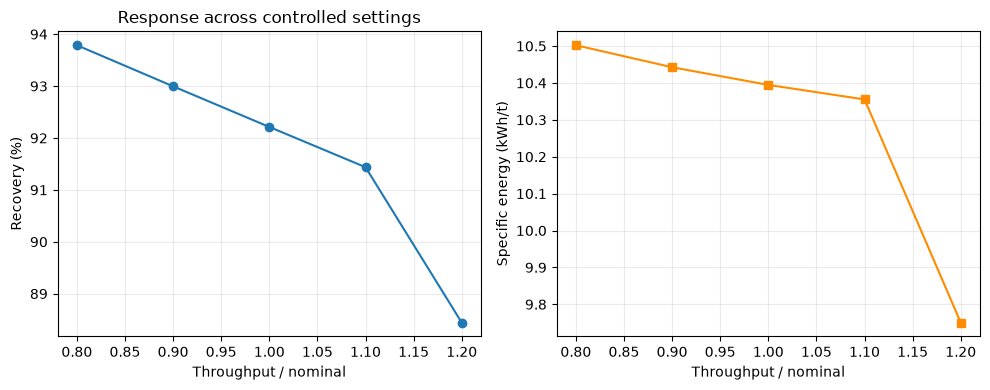

In [10]:
# Compare recovery and specific energy from the executed circuit runs.
import matplotlib.pyplot as plt
factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_1, response_2, response_3, response_4, response_5]
recovery = [run.metrics['recovery_pct'] for run in runs]
energy = [run.metrics['specific_energy_total_kwh_t'] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, recovery, marker='o')
axes[0].set(xlabel='Throughput / nominal', ylabel='Recovery (%)', title='Response across controlled settings')
axes[1].plot(factors, energy, marker='s', color='darkorange')
axes[1].set(xlabel='Throughput / nominal', ylabel='Specific energy (kWh/t)')
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()

In the level 3 05 uncertainty analysis, read this size response alongside the recovery and energy panels rather than as a substitute. At level 3, a constant grind target in this 05 uncertainty case can keep P80 nearly unchanged while power limits, recycle and residence alter other outputs. For 05 uncertainty at level 3, retain model flags and the mass-balance audit with the result.

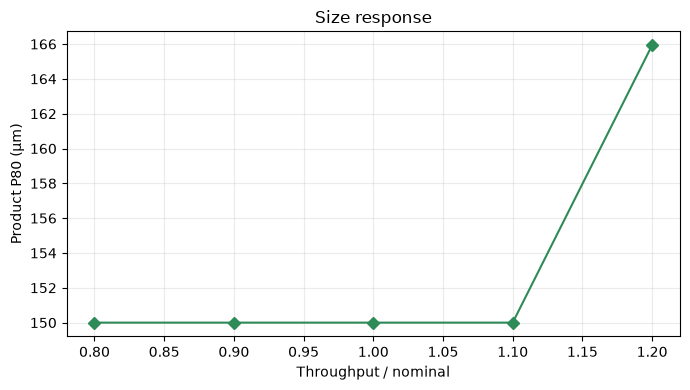

In [11]:
# Show product size separately because it is measured in micrometres, not energy or recovery.
fig, ax = plt.subplots(figsize=(7, 4))
sizes = [run.metrics['p80_um'] for run in runs]
ax.plot(factors, sizes, marker='D', color='seagreen')
ax.set(xlabel='Throughput / nominal', ylabel='Product P80 (µm)', title='Size response')
ax.grid(True, alpha=0.25)
fig.tight_layout()

At level 3 in 05 uncertainty, interpretation 1 is that a scenario spread is conditional on the chosen distributions, dependence assumptions, sample design and process equations. At level 3 in 05 uncertainty, interpretation 2 is that oreFlow's uncertainty propagation samples bounded operating and ore factors, runs the exact circuit engine and summarizes response quantiles and constraint probabilities. At level 3 in 05 uncertainty, interpretation 3 is that a Sobol decomposition asks how input variation contributes to output variance under its sampling assumptions. At level 3 in 05 uncertainty, interpretation 4 is that it does not assign probabilities to the ore body or establish causation. At level 3 in 05 uncertainty, interpretation 5 is that first-order and total-order indices answer different questions because total order includes interactions. At level 3 in 05 uncertainty, interpretation 6 is that bootstrap half-widths describe estimator stability for the design, not uncertainty about the real plant. At level 3 in 05 uncertainty, interpretation 7 is that always report the random seed, base sample count, input bounds, rejected draws and whether output was constant at numerical tolerance. At level 3 in 05 uncertainty, interpretation 8 is that independent draws can create physically implausible combinations when geological variables co-vary, while narrow bounds can make an influential factor appear unimportant. At level 3 in 05 uncertainty, interpretation 9 is that separate input uncertainty from uncertain model structure and measurement error. At level 3 in 05 uncertainty, interpretation 10 is that to interpret a decision, propagate calibrated distributions, compare predicted intervals with held-out plant campaigns and assess whether the ranking of operating choices is stable. At level 3 in 05 uncertainty, interpretation 11 is that the present authored scenarios support method inspection and reproducibility only. At level 3 in 05 uncertainty, interpretation 12 is that they do not provide a probability forecast for a mine or plant.

## Results

**Answer:** In this level 3 05 uncertainty lesson, the executed circuit reports recovery of 93.788 percent at the first controlled throughput setting for Estimate variance-based input sensitivity.

The indices rank variance contributions under the assumed independent factors and the selected small sample. Overlapping or wide half-widths indicate weak separation. Sobol indices describe this model's variance structure; they are not causal effects observed in a plant.

## Summary

You ran a published variance-based sensitivity method through OreFlow's implementation. Treat the small design as a teaching experiment, and consult the larger committed analysis and its documented bootstrap limitations before quoting results.

## References

- https://doi.org/10.1016/j.cpc.2009.09.018
- https://doi.org/10.21105/joss.00097